Fichier lu avec succès: /home/kaoutar/Desktop/data/ACT_CD_CREDIT_MDM28032025.txt, encodage: latin1
Fichier lu avec succès: /home/kaoutar/Desktop/data/ACT_CD_GETCHQ_MDM28032025.txt, encodage: latin1
Fichier lu avec succès: /home/kaoutar/Desktop/data/ACT_CD_OPERATIONS_AGENCE_MDM20032025.txt, encodage: latin1
Fichier lu avec succès: /home/kaoutar/Desktop/data/ACT_CD_PAI_VIGNETTE_MDM20032025.txt, encodage: latin1


/tmp/ipykernel_74276/1753039881.py:21: DtypeWarning: Columns (3,5) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path, sep=separator, encoding=encoding, on_bad_lines='skip')


Fichier lu avec succès: /home/kaoutar/Desktop/data/ACT_CD_PRODUIT_MDM20032025.txt, encodage: latin1
Fichier lu avec succès: /home/kaoutar/Desktop/data/ACT_CD_SOLDE_CLIENT_MDM28032025.txt, encodage: latin1
Fichier lu avec succès: /home/kaoutar/Desktop/data/ACT_CD_STAT_CONNEXION_MDM28032025.txt, encodage: latin1
Fichier lu avec succès: /home/kaoutar/Desktop/data/ACT_CD_TRANSA_MDM20032025.txt, encodage: latin1
Fichier lu avec succès: /home/kaoutar/Desktop/data/ACT_CD_TRANSFERTS_COMPTE_MDMV20032025.txt, encodage: latin1
Fichier lu avec succès: /home/kaoutar/Desktop/data/ACT_EQUI_MDM28032025.txt, encodage: latin1
Fichier lu avec succès: /home/kaoutar/Desktop/data/Périmétre_projet.txt, encodage: latin1
Table GetChq: Colonne 'CONTRAT' renommée en 'RADICAL'
Table Connexion: Colonne 'CONTRAT' renommée en 'RADICAL'

=== ANALYSE DES TABLES ET IDENTIFIANTS ===
Table Crédit: 31138 identifiants uniques, 32835 lignes
Table GetChq: 106290 identifiants uniques, 144032 lignes
Table Opérations: 545232 id

TypeError: Image data of dtype object cannot be converted to float

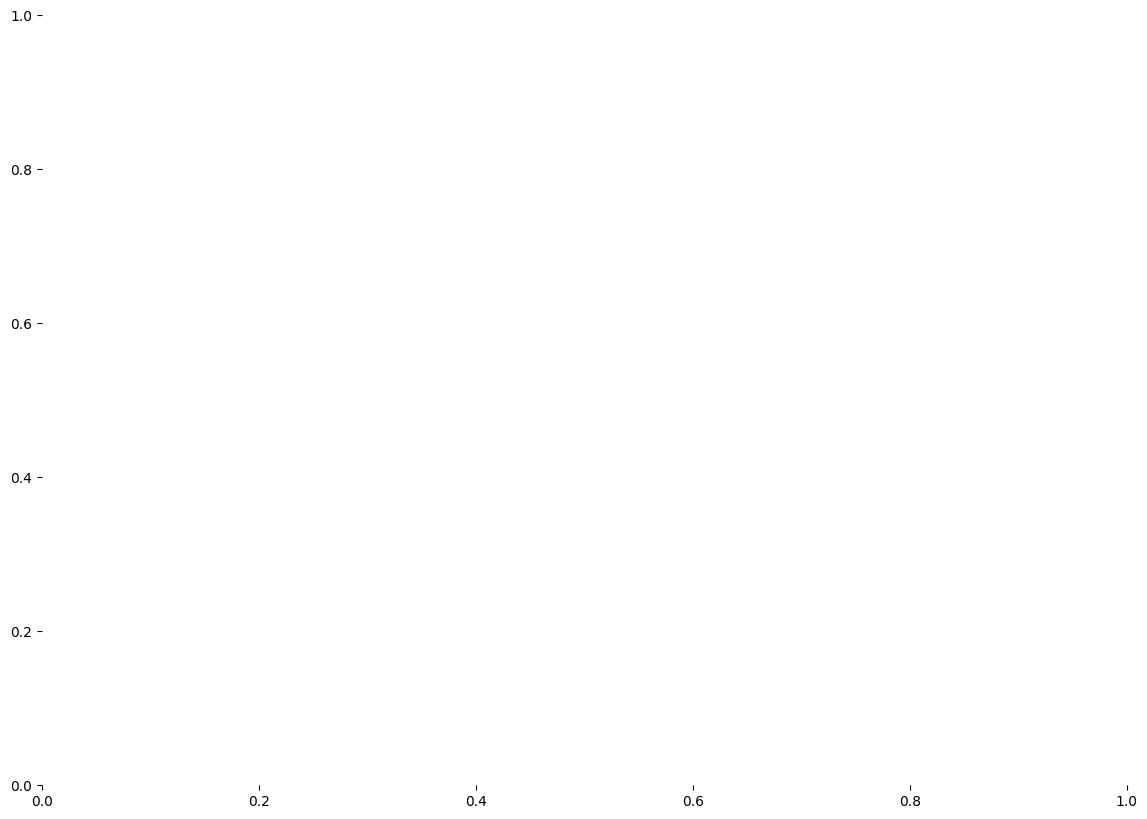

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from matplotlib_venn import venn2, venn3
import plotly.express as px
import plotly.graph_objects as go

# Définition du chemin d'accès aux données
data_path = "/home/kaoutar/Desktop/data"  # Ajustez ce chemin selon votre système

# Fonction pour essayer différents encodages
def read_with_encoding(file_path, separator='|', encodings=['latin1', 'ISO-8859-1', 'utf-8', 'cp1252', 'utf-16', 'ascii']):
    if not os.path.exists(file_path):
        print(f"Fichier non trouvé: {file_path}")
        return pd.DataFrame()
        
    for encoding in encodings:
        try:
            df = pd.read_csv(file_path, sep=separator, encoding=encoding, on_bad_lines='skip')
            print(f"Fichier lu avec succès: {file_path}, encodage: {encoding}")
            return df
        except UnicodeDecodeError:
            continue
        except Exception as e:
            print(f"Erreur lors de la lecture de {file_path}: {str(e)}")
            continue
    
    print(f"Impossible de lire le fichier {file_path} avec les encodages essayés")
    return pd.DataFrame()

# Chargement des tables
df_credit = read_with_encoding(os.path.join(data_path, 'ACT_CD_CREDIT_MDM28032025.txt'))
df_getchq = read_with_encoding(os.path.join(data_path, 'ACT_CD_GETCHQ_MDM28032025.txt'))
df_operations = read_with_encoding(os.path.join(data_path, 'ACT_CD_OPERATIONS_AGENCE_MDM20032025.txt'), separator=';')
df_vignette = read_with_encoding(os.path.join(data_path, 'ACT_CD_PAI_VIGNETTE_MDM20032025.txt'))
df_produit = read_with_encoding(os.path.join(data_path, 'ACT_CD_PRODUIT_MDM20032025.txt'))
df_solde = read_with_encoding(os.path.join(data_path, 'ACT_CD_SOLDE_CLIENT_MDM28032025.txt'))
df_conn = read_with_encoding(os.path.join(data_path, 'ACT_CD_STAT_CONNEXION_MDM28032025.txt'))
df_trans = read_with_encoding(os.path.join(data_path, 'ACT_CD_TRANSA_MDM20032025.txt'))
df_transferts = read_with_encoding(os.path.join(data_path, 'ACT_CD_TRANSFERTS_COMPTE_MDMV20032025.txt'))
df_equi = read_with_encoding(os.path.join(data_path, 'ACT_EQUI_MDM28032025.txt'))
df_perimetre = read_with_encoding(os.path.join(data_path, 'Périmétre_projet.txt'))

# Standardisation des noms de colonnes entre tables
dataframes = {
    'Crédit': df_credit,
    'GetChq': df_getchq,
    'Opérations': df_operations,
    'Vignette': df_vignette,
    'Produit': df_produit,
    'Solde': df_solde,
    'Connexion': df_conn,
    'Transactions': df_trans,
    'Transferts': df_transferts,
    'Équipements': df_equi,
    'Périmètre': df_perimetre
}

# Standardisation des identifiants (RADICAL ou CONTRAT)
for name, df in dataframes.items():
    if not df.empty:
        if 'CONTRAT' in df.columns and 'RADICAL' not in df.columns:
            df['RADICAL'] = df['CONTRAT']
            print(f"Table {name}: Colonne 'CONTRAT' renommée en 'RADICAL'")

# 1. Analyse des tables et du nombre d'identifiants
print("\n=== ANALYSE DES TABLES ET IDENTIFIANTS ===")
table_info = {}
for name, df in dataframes.items():
    if not df.empty and 'RADICAL' in df.columns:
        unique_ids = df['RADICAL'].nunique()
        total_rows = df.shape[0]
        table_info[name] = {
            'unique_ids': unique_ids,
            'total_rows': total_rows,
            'columns': df.columns.tolist(),
            'id_set': set(df['RADICAL'].unique())
        }
        print(f"Table {name}: {unique_ids} identifiants uniques, {total_rows} lignes")
    else:
        if not df.empty:
            print(f"Table {name}: Pas de colonne RADICAL trouvée. Colonnes disponibles: {df.columns.tolist()}")
        else:
            print(f"Table {name}: Dataframe vide")

# 2. Analyse des intersections entre tables
print("\n=== ANALYSE DES INTERSECTIONS ===")

# Créer une matrice d'intersection
tables_with_ids = [name for name, info in table_info.items() if 'id_set' in info]
intersection_matrix = pd.DataFrame(index=tables_with_ids, columns=tables_with_ids)

for name1 in tables_with_ids:
    for name2 in tables_with_ids:
        ids1 = table_info[name1]['id_set']
        ids2 = table_info[name2]['id_set']
        intersection = len(ids1.intersection(ids2))
        intersection_matrix.loc[name1, name2] = intersection

print("Nombre d'identifiants communs entre tables:")
print(intersection_matrix)

# 3. Pourcentage d'intersection
pct_matrix = pd.DataFrame(index=tables_with_ids, columns=tables_with_ids)

for name1 in tables_with_ids:
    for name2 in tables_with_ids:
        if name1 == name2:
            pct_matrix.loc[name1, name2] = 100.0
        else:
            ids1 = table_info[name1]['id_set']
            ids2 = table_info[name2]['id_set']
            if len(ids1) > 0:
                pct = len(ids1.intersection(ids2)) / len(ids1) * 100
                pct_matrix.loc[name1, name2] = round(pct, 1)
            else:
                pct_matrix.loc[name1, name2] = 0.0

print("\nPourcentage d'identifiants de la ligne présents dans la colonne:")
print(pct_matrix)

# 4. Visualisation des intersections avec heatmap
plt.figure(figsize=(14, 10))
sns.heatmap(pct_matrix, annot=True, cmap="YlGnBu", vmin=0, vmax=100, 
            linewidths=.5, fmt='.1f', cbar_kws={'label': '% d\'intersection'})
plt.title('Pourcentage d\'intersection des identifiants entre tables')
plt.tight_layout()
plt.savefig(os.path.join(data_path, 'intersection_heatmap.png'))
plt.show()

# 5. Ensembles d'identifiants manquants
print("\n=== IDENTIFIANTS MANQUANTS ===")
important_tables = ['Périmètre', 'Connexion', 'Transactions', 'GetChq', 'Vignette']
important_tables = [t for t in important_tables if t in tables_with_ids]

for name1 in important_tables:
    print(f"\nAnalyse pour {name1}:")
    ids1 = table_info[name1]['id_set']
    
    for name2 in important_tables:
        if name1 != name2:
            ids2 = table_info[name2]['id_set']
            missing = ids1 - ids2
            if missing:
                print(f"  - {len(missing)} identifiants ({len(missing)/len(ids1)*100:.1f}%) de {name1} sont absents dans {name2}")

# 6. Diagrammes de Venn pour visualiser les intersections entre tables importantes
# Pour les paires de tables importantes
for i, name1 in enumerate(important_tables):
    for name2 in important_tables[i+1:]:
        if name1 != name2:
            ids1 = table_info[name1]['id_set']
            ids2 = table_info[name2]['id_set']
            
            plt.figure(figsize=(10, 6))
            venn2([ids1, ids2], (name1, name2))
            plt.title(f'Intersection entre {name1} et {name2}')
            plt.savefig(os.path.join(data_path, f'venn_{name1}_{name2}.png'))
            plt.show()

# Pour des triplets de tables importantes (si vous avez au moins 3 tables)
if len(important_tables) >= 3:
    combinations = [(important_tables[i], important_tables[j], important_tables[k]) 
                   for i in range(len(important_tables)) 
                   for j in range(i+1, len(important_tables)) 
                   for k in range(j+1, len(important_tables))]
    
    # Limiter à quelques combinaisons importantes
    key_combinations = combinations[:3]  # Prendre les 3 premières combinaisons
    
    for names in key_combinations:
        ids_sets = [table_info[name]['id_set'] for name in names]
        
        plt.figure(figsize=(10, 6))
        venn3(ids_sets, names)
        plt.title(f'Intersection entre {", ".join(names)}')
        plt.savefig(os.path.join(data_path, f'venn_{"_".join(names)}.png'))
        plt.show()

# 7. Analyse de la distribution des identifiants à travers les tables
all_ids = set()
for name in tables_with_ids:
    all_ids.update(table_info[name]['id_set'])

id_presence = {}
for id_val in all_ids:
    presence_count = sum(1 for name in tables_with_ids if id_val in table_info[name]['id_set'])
    id_presence[id_val] = presence_count

presence_df = pd.DataFrame.from_dict(id_presence, orient='index', columns=['count'])
presence_counts = presence_df['count'].value_counts().sort_index()

plt.figure(figsize=(12, 6))
ax = presence_counts.plot(kind='bar')
plt.title('Distribution des identifiants par nombre de tables où ils apparaissent')
plt.xlabel('Nombre de tables')
plt.ylabel('Nombre d\'identifiants')
plt.tight_layout()

# Ajouter des étiquettes sur les barres
for i, v in enumerate(presence_counts):
    ax.text(i, v + 0.1, str(v), ha='center')

plt.savefig(os.path.join(data_path, 'distribution_presence.png'))
plt.show()

print("\nDistribution des identifiants par nombre de tables:")
for count, num_ids in presence_counts.items():
    print(f"{num_ids} identifiants apparaissent dans exactement {count} tables ({num_ids/len(all_ids)*100:.1f}%)")

# 8. Identifier les identifiants spécifiques qui posent problème
print("\n=== EXEMPLES D'IDENTIFIANTS PROBLÉMATIQUES ===")

# Identifiants qui devraient être dans toutes les tables importantes mais sont manquants dans certaines
if 'Périmètre' in table_info:
    perimetre_ids = table_info['Périmètre']['id_set']
    problem_ids = {}
    
    for name in important_tables:
        if name != 'Périmètre':
            missing = perimetre_ids - table_info[name]['id_set']
            if missing:
                # Prendre jusqu'à 5 exemples
                examples = list(missing)[:5]
                problem_ids[name] = examples
    
    if problem_ids:
        print("Exemples d'identifiants du périmètre manquants dans d'autres tables importantes:")
        for name, examples in problem_ids.items():
            print(f"  - Manquant dans {name}: {', '.join(map(str, examples))}")

# 9. Analyse des indicateurs clés après fusion
print("\n=== SIMULATION DE LA FUSION ET INDICATEURS CLÉS ===")

# Créer un dataframe de base avec tous les identifiants
all_ids_list = list(all_ids)
df_main_simulated = pd.DataFrame({'RADICAL': all_ids_list})

# Simuler la fusion pour les indicateurs clés
if 'Connexion' in table_info:
    conn_ids = table_info['Connexion']['id_set']
    connected_ids = set()
    if not df_conn.empty and 'CONNECTION' in df_conn.columns:
        connected_ids = set(df_conn[df_conn['CONNECTION'] != 'Jamais Connecte']['RADICAL'].unique())
    df_main_simulated['is_connected'] = df_main_simulated['RADICAL'].isin(connected_ids)
    df_main_simulated['in_conn_table'] = df_main_simulated['RADICAL'].isin(conn_ids)

if 'Transactions' in table_info:
    trans_ids = table_info['Transactions']['id_set']
    transaction_ids = set()
    if not df_trans.empty and 'NOMBRE_OPE' in df_trans.columns:
        df_trans['NOMBRE_OPE'] = pd.to_numeric(df_trans['NOMBRE_OPE'], errors='coerce')
        trans_by_client = df_trans.groupby('RADICAL')['NOMBRE_OPE'].sum().reset_index()
        transaction_ids = set(trans_by_client[trans_by_client['NOMBRE_OPE'] >= 2]['RADICAL'].unique())
    df_main_simulated['has_transactions'] = df_main_simulated['RADICAL'].isin(transaction_ids)
    df_main_simulated['in_trans_table'] = df_main_simulated['RADICAL'].isin(trans_ids)

if 'GetChq' in table_info:
    getchq_ids = table_info['GetChq']['id_set']
    df_main_simulated['used_getchq'] = df_main_simulated['RADICAL'].isin(getchq_ids)

if 'Vignette' in table_info:
    vignette_ids = table_info['Vignette']['id_set']
    df_main_simulated['paid_vignette'] = df_main_simulated['RADICAL'].isin(vignette_ids)

# Créer la variable cible simulée
if all(col in df_main_simulated.columns for col in ['is_connected', 'has_transactions', 'used_getchq', 'paid_vignette']):
    df_main_simulated['appetent'] = df_main_simulated['is_connected'] & (
        df_main_simulated['has_transactions'] | 
        df_main_simulated['used_getchq'] | 
        df_main_simulated['paid_vignette']
    )
    
    # Statistiques sur la variable cible
    print(f"Nombre total d'identifiants uniques: {len(df_main_simulated)}")
    print(f"Clients connectés: {df_main_simulated['is_connected'].sum()} ({df_main_simulated['is_connected'].mean()*100:.1f}%)")
    print(f"Clients avec transactions: {df_main_simulated['has_transactions'].sum()} ({df_main_simulated['has_transactions'].mean()*100:.1f}%)")
    print(f"Clients ayant utilisé GetChq: {df_main_simulated['used_getchq'].sum()} ({df_main_simulated['used_getchq'].mean()*100:.1f}%)")
    print(f"Clients ayant payé une vignette: {df_main_simulated['paid_vignette'].sum()} ({df_main_simulated['paid_vignette'].mean()*100:.1f}%)")
    print(f"Clients appétents (simulation): {df_main_simulated['appetent'].sum()} ({df_main_simulated['appetent'].mean()*100:.1f}%)")

# 10. Sauvegarde des données d'analyse
# Sauvegarder les matrices d'intersection pour référence
intersection_matrix.to_csv(os.path.join(data_path, 'intersection_matrix.csv'))
pct_matrix.to_csv(os.path.join(data_path, 'pct_intersection_matrix.csv'))

# Sauvegarder la simulation
if 'appetent' in df_main_simulated.columns:
    df_main_simulated.to_csv(os.path.join(data_path, 'df_fusion_simulation.csv'), index=False)

In [ ]:
import pandas as pd
import os

# Définir le chemin du dossier contenant tous les fichiers
data_path = "/home/kaoutar/Desktop/data"

# Charger la table périmètre qui servira de base
perimetre_path = os.path.join(data_path, "Périmétre_projet.txt")
df_perimetre = pd.read_csv(perimetre_path, encoding='latin1', sep='|', low_memory=False)

# Initialiser le dataframe final avec la table périmètre
df_final = df_perimetre.copy()
print(f"Table périmètre chargée avec {len(df_perimetre)} lignes et {df_perimetre.shape[1]} colonnes")

# Liste des tables à joindre avec leurs chemins complets
tables_a_joindre = {
    'credit': os.path.join(data_path, "ACT_CD_CREDIT_MDM28032025.txt"),
    'solde': os.path.join(data_path, "ACT_CD_SOLDE_CLIENT_MDM28032025.txt"),
    'operations': os.path.join(data_path, "ACT_CD_OPERATIONS_AGENCE_MDM20032025.txt"),
    'produit': os.path.join(data_path, "ACT_CD_PRODUIT_MDM20032025.txt"),
    'connexion': os.path.join(data_path, "ACT_CD_STAT_CONNEXION_MDM28032025.txt"),
    'transactions': os.path.join(data_path, "ACT_CD_TRANSA_MDM20032025.txt"),
    'equipements': os.path.join(data_path, "ACT_EQUI_MDM28032025.txt"),
    'transferts': os.path.join(data_path, "ACT_CD_TRANSFERTS_COMPTE_MDMV20032025.txt"),
    'getchq': os.path.join(data_path, "ACT_CD_GETCHQ_MDM28032025.txt"),
    'vignette': os.path.join(data_path, "ACT_CD_PAI_VIGNETTE_MDM20032025.txt")
}

# Pour les tables volumineuses, définir des fonctions d'agrégation
aggregation_functions = {
    'operations': {
        'MONTANT': ['sum', 'mean', 'count', 'max', 'min'],
        'DATE_OPERATION': ['min', 'max', 'count']
    },
    'transactions': {
        'MONTANT': ['sum', 'mean', 'count'],
        'DATE': ['min', 'max']
    },
    'connexion': {
        'DATE_CONNEXION': ['min', 'max', 'count']
    }
    # Ajoutez d'autres tables selon vos besoins
}

# Effectuer les jointures une par une
for table_name, file_path in tables_a_joindre.items():
    print(f"Traitement de la table {table_name}...")
    
    try:
        # Charger la table
        df_temp = pd.read_csv(file_path, encoding='latin1', sep='|', low_memory=False)
        print(f"  Table {table_name} chargée avec {len(df_temp)} lignes")
        
        # S'assurer que la colonne d'identifiant a le même nom
        if 'CONTRAT' in df_temp.columns and 'RADICAL' not in df_temp.columns:
            df_temp.rename(columns={'CONTRAT': 'RADICAL'}, inplace=True)
            print(f"  Colonne CONTRAT renommée en RADICAL dans {table_name}")
        
        # Pour les tables volumineuses, agréger avant la jointure
        if table_name in aggregation_functions:
            print(f"  Agrégation de la table {table_name}...")
            df_agg = df_temp.groupby('RADICAL').agg(aggregation_functions[table_name])
            
            # Aplatir les noms de colonnes multi-index
            df_agg.columns = [f"{table_name}_{col[0]}_{col[1]}" for col in df_agg.columns]
            df_agg = df_agg.reset_index()
            
            print(f"  Table {table_name} agrégée: {len(df_agg)} lignes")
            df_temp = df_agg
        else:
            # Pour les tables non agrégées, préfixer les colonnes (sauf RADICAL)
            cols_to_rename = {col: f"{table_name}_{col}" for col in df_temp.columns if col != 'RADICAL'}
            df_temp = df_temp.rename(columns=cols_to_rename)
        
        # Jointure
        print(f"  Jointure avec la table {table_name}...")
        before_join = len(df_final)
        df_final = df_final.merge(df_temp, on='RADICAL', how='left')
        
        # Vérifier le succès de la jointure
        cols_from_table = [col for col in df_final.columns if col.startswith(f"{table_name}_") or 
                           (table_name in aggregation_functions and col.startswith(table_name))]
        
        missing_after_join = df_final[cols_from_table].isnull().all(axis=1).sum()
        match_count = before_join - missing_after_join
        match_percent = (match_count / before_join) * 100
        
        print(f"  Résultat de la jointure avec {table_name}: {match_count} correspondances ({match_percent:.2f}%)")
        
        # Créer un indicateur de présence/absence pour cette table
        df_final[f"has_{table_name}"] = (~df_final[cols_from_table].isnull().all(axis=1)).astype(int)
        
    except Exception as e:
        print(f"Erreur lors du traitement de la table {table_name}: {str(e)}")

# Vérifier la taille finale
print(f"Dimensions de la table finale: {df_final.shape}")

# Sauvegarder la table finale
output_path = os.path.join(data_path, "table_finale_ml.csv")
df_final.to_csv(output_path, index=False)
print(f"Table finale sauvegardée dans {output_path}")

# Afficher un résumé des indicateurs de présence
indicators = [col for col in df_final.columns if col.startswith("has_")]
presence_summary = df_final[indicators].sum().sort_values(ascending=False)
print("\nRésumé des correspondances:")
for table, count in presence_summary.items():
    table_name = table.replace("has_", "")
    percent = (count / len(df_final)) * 100
    print(f"{table_name}: {count} correspondances ({percent:.2f}%)")

Table périmètre chargée avec 1051499 lignes et 8 colonnes
Traitement de la table credit...
  Table credit chargée avec 32835 lignes
  Jointure avec la table credit...
  Résultat de la jointure avec credit: 31177 correspondances (2.97%)
Traitement de la table solde...
  Table solde chargée avec 11005299 lignes
  Jointure avec la table solde...
  Résultat de la jointure avec solde: 1047145 correspondances (99.28%)
Traitement de la table operations...
  Table operations chargée avec 3846343 lignes
  Agrégation de la table operations...
Erreur lors du traitement de la table operations: 'RADICAL'
Traitement de la table produit...
  Table produit chargée avec 1737390 lignes
  Jointure avec la table produit...
